# PPO: Vision Transformer (ViT) và CNN + LSTM trên Ms. Pacman

Huấn luyện hai kiến trúc mới (`arch="vit"`, `arch="lstm"`) với cùng thiết lập như các notebook trước (`n_envs=32`, `n_steps=512`, `death_penalty=2.5`, xám 84x84), lưu vào `runs/` bằng `save_run`, rồi so với run CNN cũ.

- Đặt `SMOKE = True` để chạy thử ~2 phút trước khi train thật.
- Run đã có file `.pt` + `_log.npy` thì bỏ qua, nên chạy lại cell train sau khi bị ngắt vẫn tiếp tục được (run dở sẽ train lại từ đầu).
- Tốc độ đo trên RTX 3070 Ti: ViT và LSTM đều ~440 bước/s, tức 1 triệu bước ≈ 38 phút.

In [ ]:
from pathlib import Path
import numpy as np
from pacman_rl import PPOConfig, train_ppo, get_device, random_baseline
from pacman_rl.runs import save_run, load_run, list_runs
from pacman_rl.plotting import compare
from pacman_rl.evaluation import ppo_policy, evaluate

device = get_device()
print(device)

cuda


## 1. Tham số

In [ ]:
SMOKE = False
STEPS = 16_384 if SMOKE else 2_000_000
SEEDS = [0]
RGB = False                    # True: đầu vào RGB (12 kênh)
RUN_DIR = "runs"

# mỗi nhánh = một kiến trúc + lr riêng. ViT thường cần lr nhỏ hơn CNN
ARMS = {
    "vit":  dict(arch="vit",  lr=1e-4),
    "lstm": dict(arch="lstm", lr=2.5e-4),
}

def run_name(arm, seed):
    return ("smoke_" if SMOKE else "") + f"{arm}_dp25" + ("_rgb" if RGB else "") + f"_s{seed}"

def make_cfg(seed, **kw):
    return PPOConfig(
        total_steps=STEPS, seed=seed, death_penalty=2.5, step_penalty=0.1, rgb_scale=RGB,
        n_envs=4 if SMOKE else 32,
        n_steps=128 if SMOKE else 512,
        n_minibatches=4,
        save_every=200 if SMOKE else 50_000,
        log_every=2 if SMOKE else 50,
        **kw)

print([run_name(a, s) for s in SEEDS for a in ARMS], STEPS)

['vit_dp25_s0', 'lstm_dp25_s0'] 2000000


## 2. Huấn luyện
LSTM: PPO chia minibatch theo env (giữ nguyên chuỗi 512 bước), nên `n_envs` phải chia hết cho `n_minibatches` (32/4 = 8 env mỗi minibatch). Trạng thái ẩn bị reset mỗi khi mất mạng hoặc hết ván.

In [7]:
for seed in SEEDS:
    for arm, kw in ARMS.items():
        name = run_name(arm, seed)
        if Path(f"{RUN_DIR}/{name}.pt").exists() and Path(f"{RUN_DIR}/{name}_log.npy").exists():
            print(f"bỏ qua {name} (đã có)")
            continue
        print(f"=== {name} ===")
        result = train_ppo(cfg=make_cfg(seed, **kw), model=None, save_path=f"{RUN_DIR}/{name}.pt", device=device)
        save_run(result, RUN_DIR, name, append=False)

=== vit_dp25_s0 ===
PPO: 122 updates x 16384 mẫu = 1,998,848 bước, 32 env song song
Update 50/122 | step 819,200 | avg score(20) 634 | 3989 lượt | 205 bước/lượt | 0.23 viên NL/lượt | 0.16 ma/lượt | phạt chết 2.5 bước 0.000 | entropy 1.922 | KL 0.0009 | clipfrac 0.001 | 638 steps/s
Update 100/122 | step 1,638,400 | avg score(20) 565 | 3755 lượt | 218 bước/lượt | 0.32 viên NL/lượt | 0.23 ma/lượt | phạt chết 2.5 bước 0.000 | entropy 1.952 | KL 0.0003 | clipfrac 0.001 | 645 steps/s
Update 122/122 | step 1,998,848 | avg score(20) 474 | 1672 lượt | 216 bước/lượt | 0.31 viên NL/lượt | 0.20 ma/lượt | phạt chết 2.5 bước 0.000 | entropy 1.944 | KL -0.0001 | clipfrac 0.000 | 648 steps/s
=== lstm_dp25_s0 ===
PPO: 122 updates x 16384 mẫu = 1,998,848 bước, 32 env song song
Update 50/122 | step 819,200 | avg score(20) 677 | 4245 lượt | 193 bước/lượt | 0.15 viên NL/lượt | 0.10 ma/lượt | phạt chết 2.5 bước 0.000 | entropy 1.927 | KL 0.0083 | clipfrac 0.287 | 1196 steps/s
Update 100/122 | step 1,638,400

## 3. Đường học và so sánh với CNN cũ

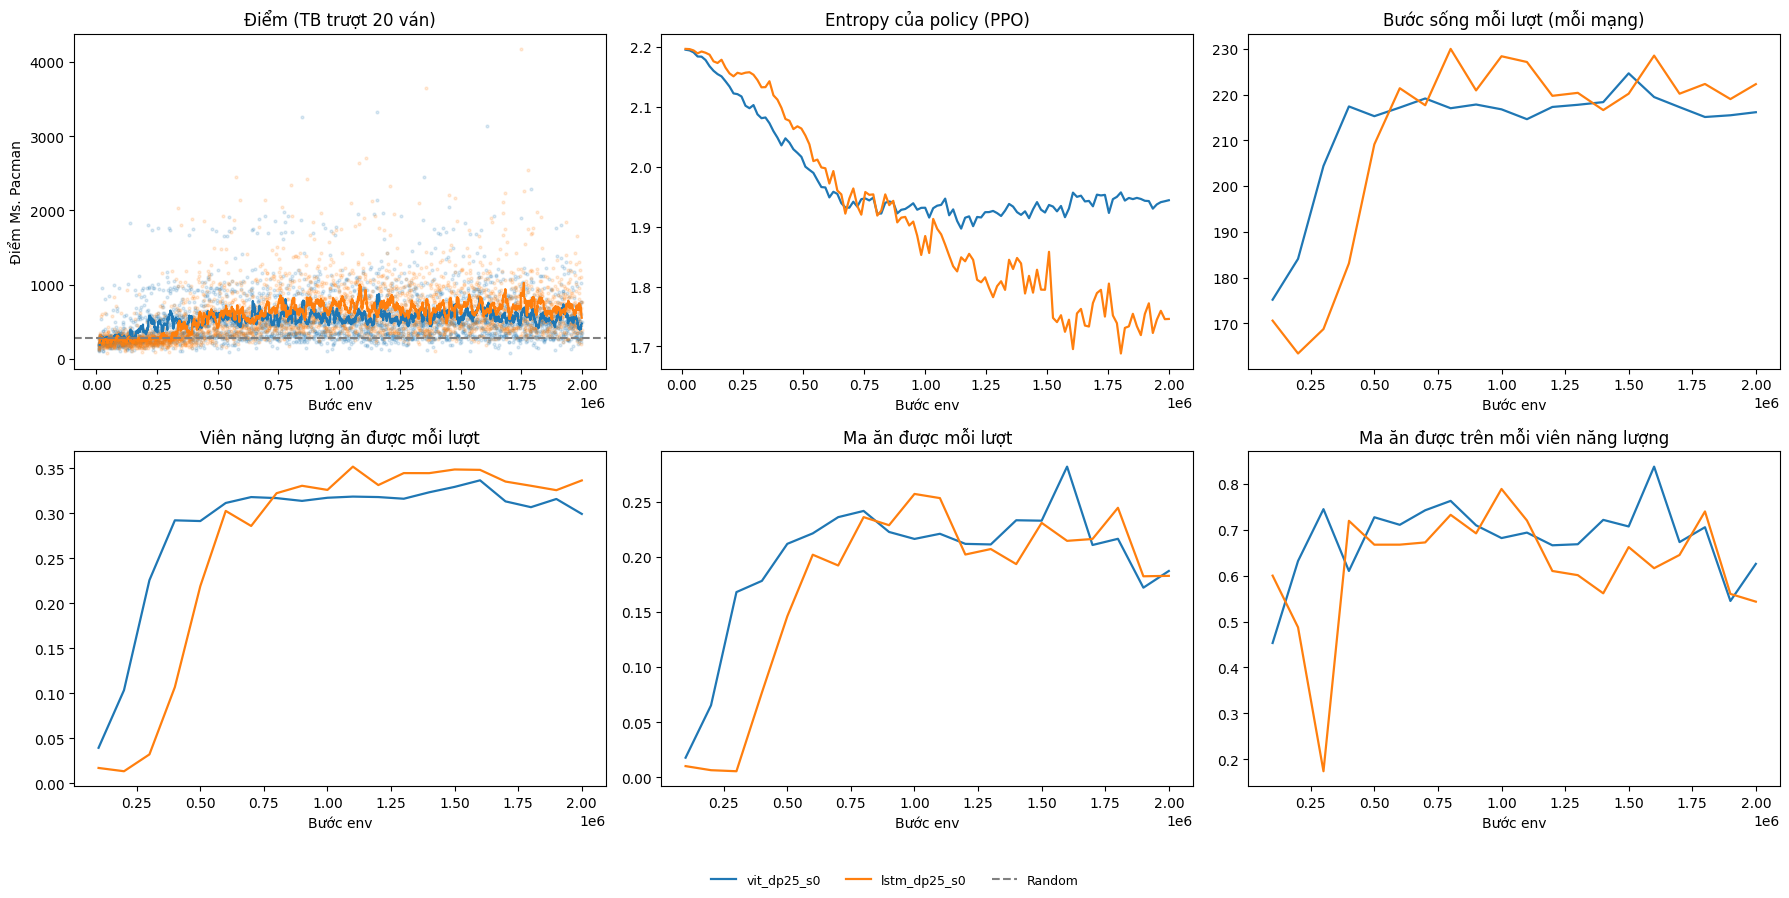

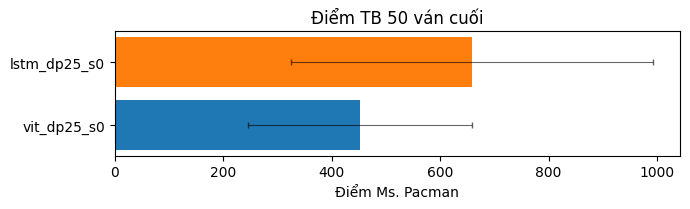

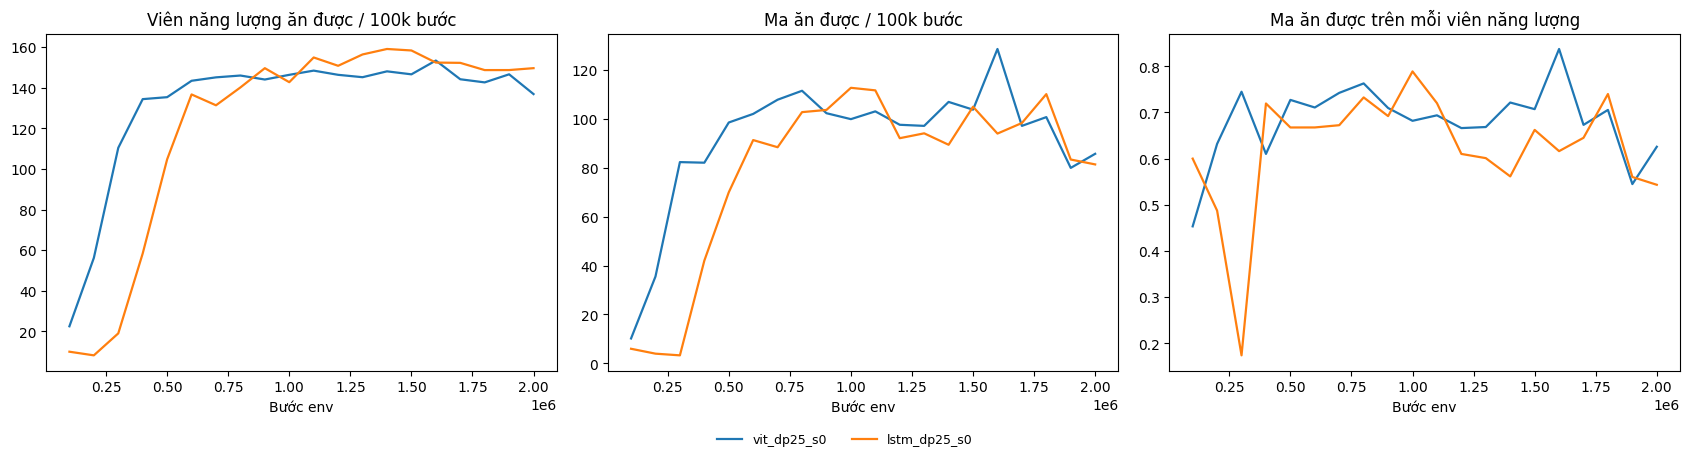

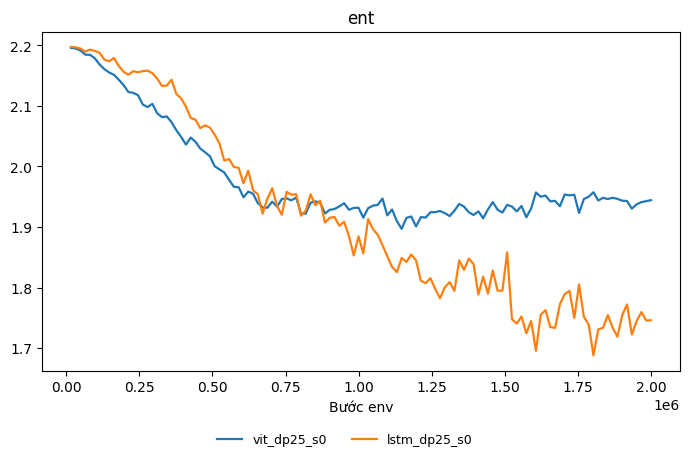

In [8]:
# thêm run CNN cũ (nếu có) để so sánh cùng thiết lập: gray, death_penalty 2.5
baseline = [n for n in ("ab_gray_dp25",) if n in list_runs(RUN_DIR)]
names = baseline + [run_name(a, s) for s in SEEDS for a in ARMS]
runs = compare(names=names, directory=RUN_DIR, random_scores=random_baseline(5),
               metrics=("ent",), device=device, save_path=f"{RUN_DIR}/vit_lstm_compare.png")

## 4. Chấm điểm (seed cố định, cùng ván cho mọi model)

In [9]:
N_EVAL = 3 if SMOKE else 20
rows = {}
for n in names:
    model = load_run(RUN_DIR, n, "ppo", device).model.to(device).eval()
    rows[n] = evaluate(ppo_policy(model, device), n_episodes=N_EVAL, seed=1000)
    print(f"{n:28s} TB {np.mean(rows[n]):7.0f} | std {np.std(rows[n]):6.0f} | max {np.max(rows[n]):6.0f}")

vit_dp25_s0                  TB     650 | std    288 | max   1130
lstm_dp25_s0                 TB     577 | std    207 | max   1080


In [10]:
from pacman_rl.evaluation import watch

WATCH_EPISODES = 1
for n in names:
    model = load_run(RUN_DIR, n, "ppo", device).model.to(device).eval()
    print(f"=== đang chiếu {n} ===")
    watch(ppo_policy(model, device, greedy=False), episodes=WATCH_EPISODES)   # greedy=True nếu muốn chọn action xác suất cao nhất

=== đang chiếu vit_dp25_s0 ===
[play] ván 1: 1170 điểm (843 bước)
=== đang chiếu lstm_dp25_s0 ===
[play] ván 1: 1130 điểm (827 bước)
